In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import shap
from matplotlib import pyplot as plt

In [8]:
def plot_feature_importances(X_train, y_train, X_test, y_test, super_title, color_scheme = "green", file_name=None):

    # Initialize the Scaler
    scaler = StandardScaler()

    # Fit strictly on the training set and transform
    # This prevents test set variance metrics from leaking into your training loop
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    continuous_cols = ['log_price', 'log_achievements', 'log_dlc_count', 'log_total_languages', 'num_tags', 'num_categories']

    X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
    X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

    # Fit rf regressor to training data
    rf = RandomForestRegressor( 
        random_state=42, 
        n_jobs=-1, 
        max_depth=15, 
        min_samples_leaf=50,
        n_estimators=100
    )
    rf.fit(X_train_scaled, y_train)

    # Fit permutation feature importance
    perm_importance = permutation_importance(
        rf, 
        X_test_scaled, 
        y_test, 
        n_repeats=20, 
        random_state=42, 
        scoring="neg_median_absolute_error",
        n_jobs=-1
        )

    # Fit SHAP feature importance
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(X_test_scaled)

    # Extract importance values from each method
    rf_importance_values = rf.feature_importances_
    perm_importance_values = perm_importance.importances_mean
    perm_importance_std = perm_importance.importances_std  
    shap_importance_values = np.mean(np.abs(shap_values), axis=0)

    feature_names = X_train.columns if hasattr(X_train, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]
    feature_names_arr = np.array(feature_names)
    
    # Bundle the data together for iterative plotting
    methods = [
        ("MDI (Built-in RF)", rf_importance_values, None, "MDI"),
        ("Permutation Importance", perm_importance_values, perm_importance_std, "Negative-MAE"),
        ("SHAP (Global Absolute)", shap_importance_values, None, "SHAP Absolute")
    ]

    # Create the 1x3 subplot figure
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
    
    for i, (title, values, xerrs, score) in enumerate(methods):
        ax = axes[i]
        
        # Sort indices in ascending order for a clean horizontal bar plot layout
        sorted_idx = np.argsort(values)
        
        # Pull out sorted configurations
        sorted_features = feature_names_arr[sorted_idx]
        sorted_values = values[sorted_idx]
        
        if xerrs is not None:
            # Re-index the standard deviations to match the sorted value sequence
            sorted_xerrs = xerrs[sorted_idx]
            
            # Plot horizontal bars WITH standard deviation error caps
            ax.barh(sorted_features, sorted_values, xerr=sorted_xerrs, 
                    color=color_scheme, edgecolor='black', alpha=0.8,
                    error_kw={'ecolor': 'black', 'capsize': 4, 'elinewidth': 1.5, 'capthick': 1.5})
        else:
            # Plot standard horizontal bars for scale-invariant / static frameworks
            ax.barh(sorted_features, sorted_values, 
                    color=color_scheme, edgecolor='black', alpha=0.8)
        # Style adjustments
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.set_xlabel(f'{score} Importance Score', fontsize=12)
        ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    fig.suptitle(F"Feature Importance Analysis of {super_title}", fontsize = 16, fontweight='bold', y=0.98)

    fig.savefig(f"../outputs/figures/{file_name}.png")
        
    plt.tight_layout()
    plt.show()

In [4]:
train_set = pd.read_csv("../data/enriched/training_set.csv")
test_set = pd.read_csv("../data/enriched/test_set.csv")

index_columns = ["recent_velocity_index", "lifetime_engagement_index", "user_sentiment_index", "overall_popularity_index"]

X_train, X_test = train_set.drop(columns=index_columns), test_set.drop(columns=index_columns)

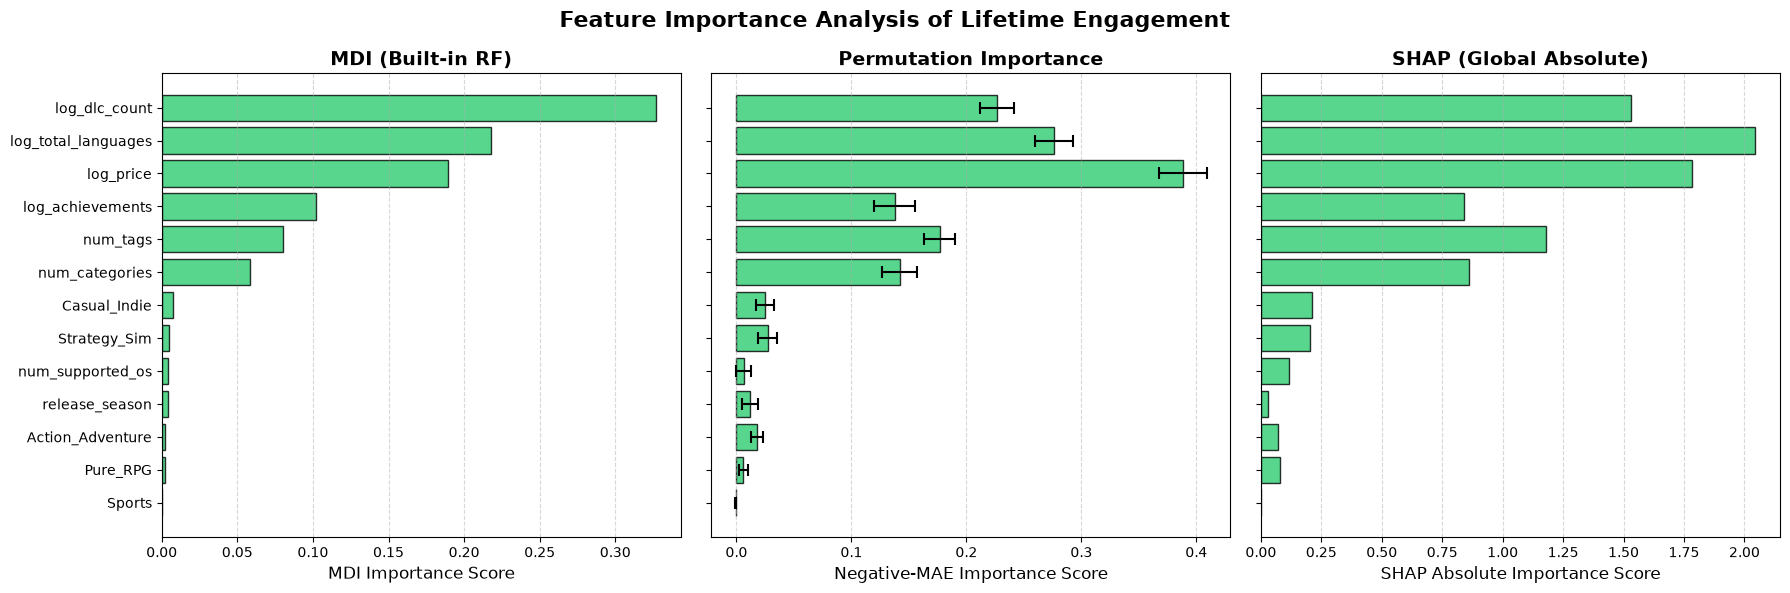

In [9]:
y_train_lifetime, y_test_lifetime = train_set["lifetime_engagement_index"], test_set["lifetime_engagement_index"]

plot_feature_importances(X_train, y_train_lifetime, X_test, y_test_lifetime, "Lifetime Engagement", color_scheme = "#2ecc71", file_name="engagement_feature_importance")


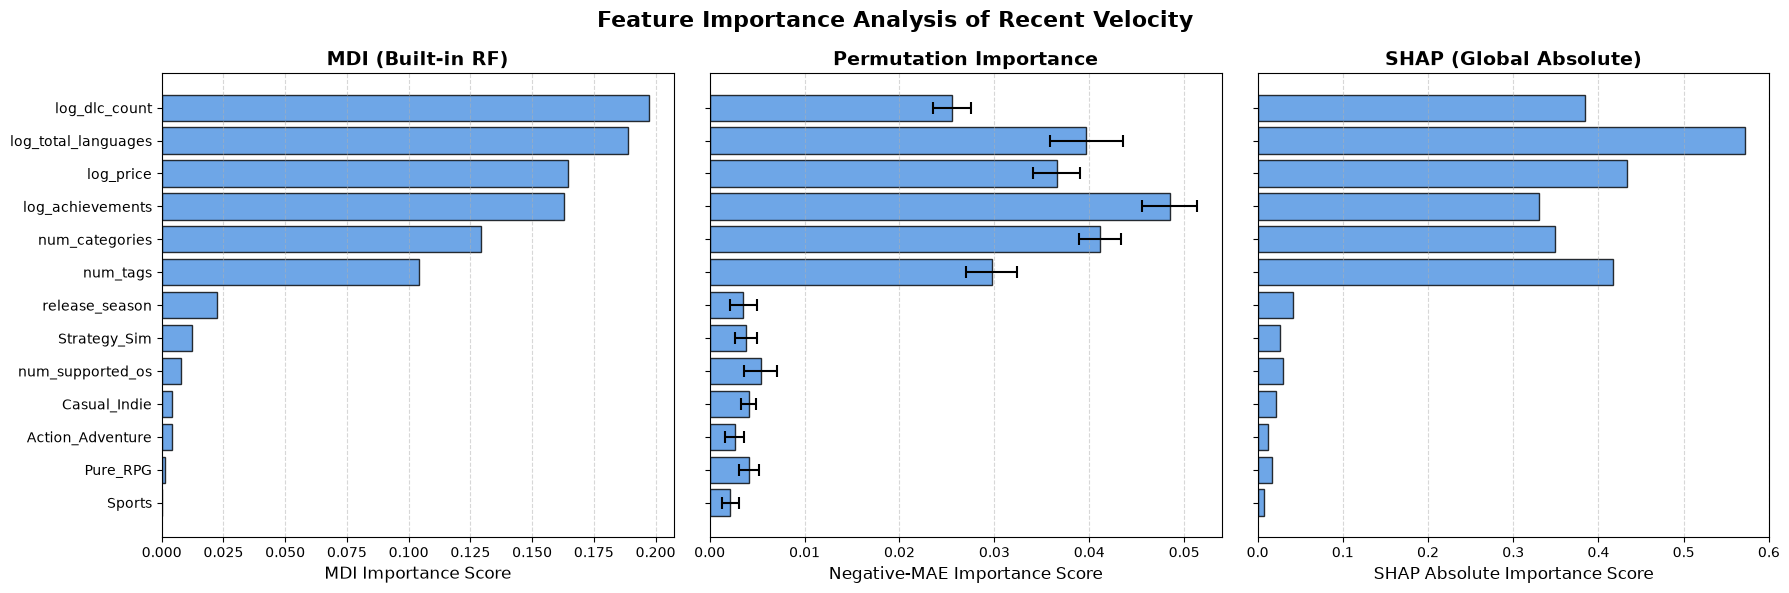

In [10]:
y_train_velocity, y_test_velocity = train_set["recent_velocity_index"], test_set["recent_velocity_index"]

plot_feature_importances(X_train, y_train_velocity, X_test, y_test_velocity, "Recent Velocity", color_scheme="#4a90e2", file_name="velocity_feature_importance")


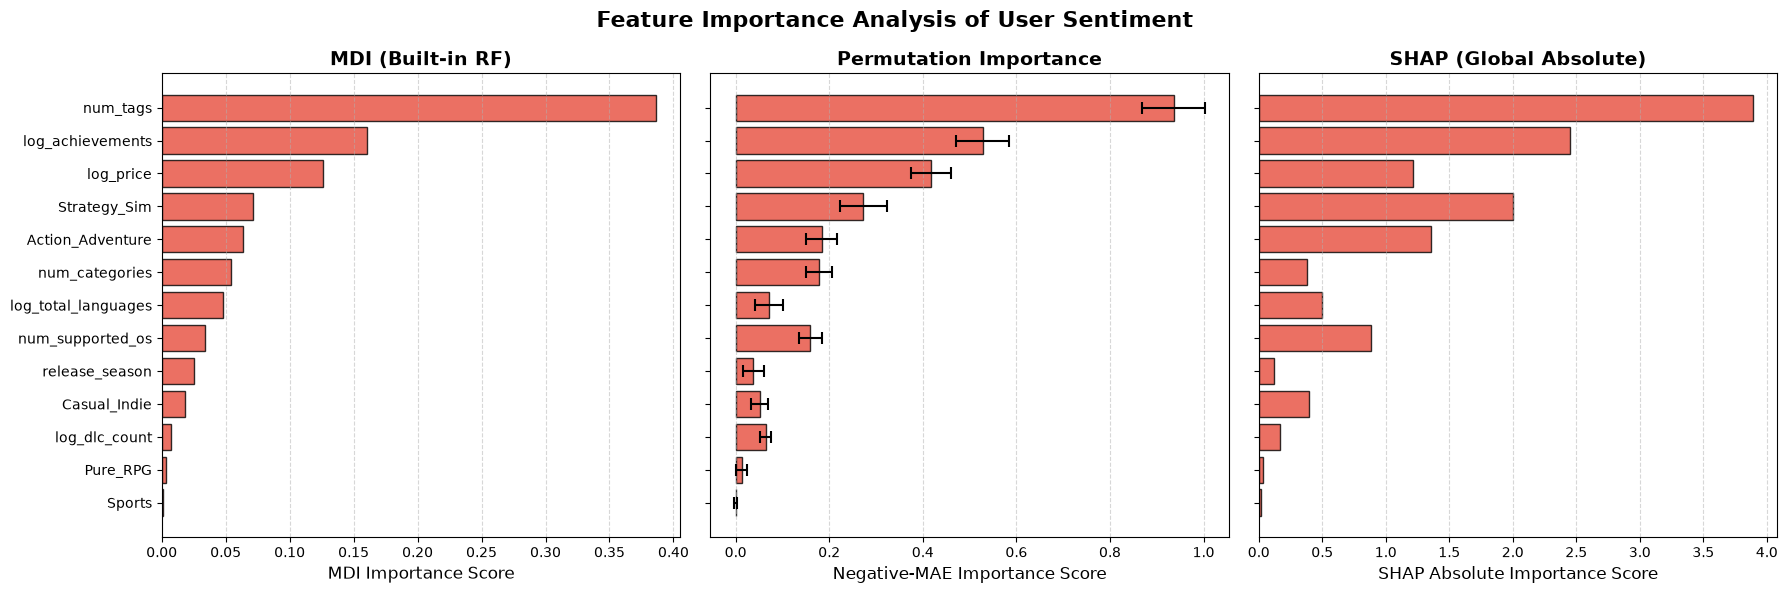

In [11]:
y_train_sentiment, y_test_sentiment = train_set["user_sentiment_index"], test_set["user_sentiment_index"]

plot_feature_importances(X_train, y_train_sentiment, X_test, y_test_sentiment, "User Sentiment", color_scheme="#e74c3c", file_name="sentiment_feature_importance")